### A6 Step 1: Preparing the PCA / factor-analysis input

PCA and FA use the treated numeric features (A3/A4), standardized, fitted on loans issued ≤ 2014.
- Candidates: numeric features with more than 2 distinct values (0/1 flags and the 36/60 term excluded); mths_since_last_delinq excluded (46% missing by design). 22 candidates, none missing.
- **Why extremes matter:** PCA is built on variances and correlations, which use squared distances. One loan 11.5 standard deviations out contributes as much variance as ~130 typical loans, and loans extreme on two fields can create correlations most borrowers don't show.
- **Count fields:** with few distinct values, log1p barely changes the picture (same bars at new positions), and the skew number improves only because the gaps shrink. So the decision uses the largest |z| instead (rule set in advance: raw max |z| > 5 → log1p).
  - log1p: num_tl_op_past_12m (11.5 → 3.8), open_acc (8.3 → 4.4), acc_open_past_24mths (7.7 → 3.1), mort_acc (7.4 → 3.0), credit_hist_months (6.4 → 3.4), inq_last_6mths (5.0 → 3.0, borderline; rule followed).
  - fico_mid kept as is (5.0 → 4.7, no loan beyond 5; skew comes from the minimum-FICO floor).
- delinq_2yrs, pub_rec, pub_rec_bankruptcies excluded from PCA: 80–88% zeros, near-binary; log1p only moves the bars (they remain model features).
- 19 inputs, standardized (mean 0, std 1) with means/stds learned on ≤ 2014 and saved in a6_spec.json. These transforms apply only to the PCA/FA input; model features are unchanged.

In [1]:
import json
import numpy as np
import pandas as pd
from pathlib import Path

train = pd.read_parquet(Path("../data/interim/train_a5.parquet"))
SPEC = json.load(open("../reports/a5_spec.json"))
FIT_CUTOFF = pd.Timestamp("2014-12-31")
TARGET = "defaulted"
fit = train[train["issue_dt"] <= FIT_CUTOFF].copy()
print(train.shape, fit.shape, len(SPEC["features"]))

(30000, 81) (14373, 81) 30


In [2]:
PCA_CANDIDATES = [c for c in SPEC["features"]
                  if pd.api.types.is_numeric_dtype(train[c])
                  and train[c].nunique() > 2                    # skip 0/1 flags and the 36/60 term
                  and c != "mths_since_last_delinq"]           # 46% missing by design ("never")

def profile_for_pca(df, cols):
    """Skew, missing, distinct values and share of zeros: is each column ready for PCA?"""
    return pd.DataFrame({
        "skew": df[cols].skew().round(2),
        "missing": df[cols].isna().sum(),
        "distinct": df[cols].nunique(),
        "zero_share": (df[cols] == 0).mean().round(3),
    }).sort_values("skew", ascending=False)

print(len(PCA_CANDIDATES), "candidates")
display(profile_for_pca(fit, PCA_CANDIDATES))

22 candidates


,skew,missing,distinct,zero_share
delinq_2yrs,5.65,0,15,0.805
pub_rec,4.61,0,9,0.842
pub_rec_bankruptcies,2.87,0,5,0.876
inq_last_6mths,1.60,0,7,0.528
fico_mid,1.42,0,37,0.000
mort_acc,1.39,0,17,0.386
num_tl_op_past_12m,1.26,0,17,0.179
open_acc,1.16,0,44,0.000
credit_hist_months,1.10,0,1515,0.000
acc_open_past_24mths,1.09,0,24,0.045


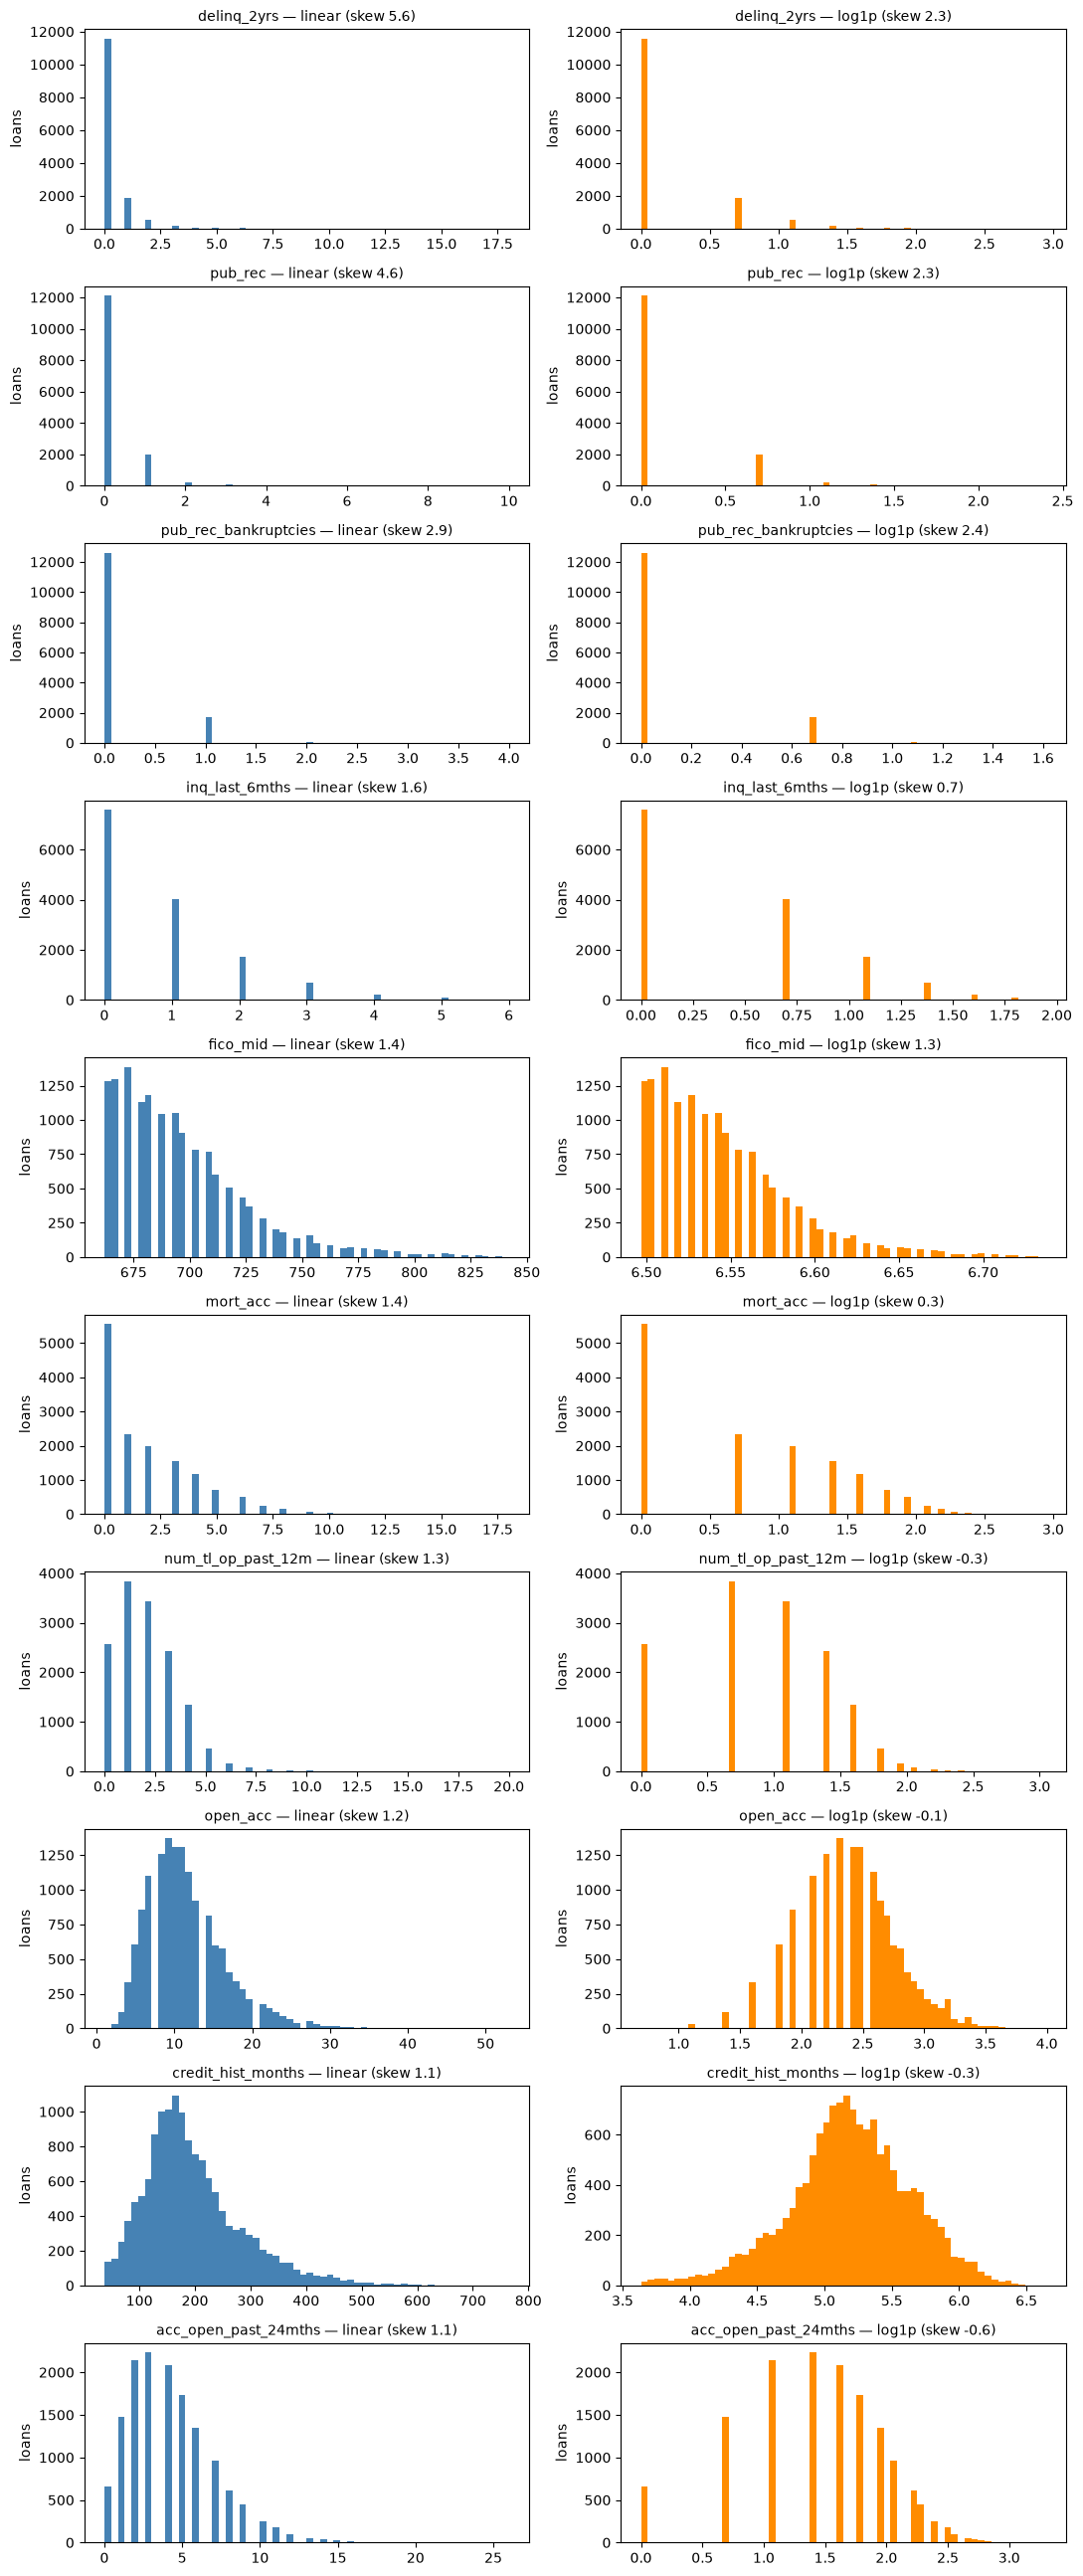

In [3]:
import matplotlib.pyplot as plt

def plot_linear_vs_log(df, cols, path=None):
    """Left: the field as it is. Right: after log1p. Skew in each title."""
    fig, axes = plt.subplots(len(cols), 2, figsize=(11, 2.6 * len(cols)))
    for row, c in zip(axes, cols):
        s = df[c].dropna()
        row[0].hist(s, bins=60, color="steelblue")
        row[0].set_title(f"{c} — linear (skew {s.skew():.1f})", fontsize=10)
        row[1].hist(np.log1p(s), bins=60, color="darkorange")
        row[1].set_title(f"{c} — log1p (skew {np.log1p(s).skew():.1f})", fontsize=10)
        for ax in row:
            ax.set_ylabel("loans")
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()

UNCERTAIN = ["delinq_2yrs", "pub_rec", "pub_rec_bankruptcies", "inq_last_6mths", "fico_mid",
             "mort_acc", "num_tl_op_past_12m", "open_acc", "credit_hist_months", "acc_open_past_24mths"]
plot_linear_vs_log(fit, UNCERTAIN, path="../reports/pca_candidates_linear_vs_log.png")

In [4]:
def skew_before_after(df, cols):
    """Skew of each column as it is and after log1p, plus share of zeros."""
    return pd.DataFrame({
        "skew_raw": df[cols].skew().round(2),
        "skew_log1p": np.log1p(df[cols]).skew().round(2),
        "zero_share": (df[cols] == 0).mean().round(3),
    })

display(skew_before_after(fit, UNCERTAIN))

,skew_raw,skew_log1p,zero_share
delinq_2yrs,5.65,2.28,0.805
pub_rec,4.61,2.35,0.842
pub_rec_bankruptcies,2.87,2.43,0.876
inq_last_6mths,1.60,0.68,0.528
fico_mid,1.42,1.28,0.000
mort_acc,1.39,0.27,0.386
num_tl_op_past_12m,1.26,-0.28,0.179
open_acc,1.16,-0.13,0.000
credit_hist_months,1.10,-0.31,0.000
acc_open_past_24mths,1.09,-0.57,0.045


In [5]:
def max_abs_z(s):
    """How many standard deviations the most extreme value sits from the mean."""
    return ((s - s.mean()) / s.std()).abs().max()

def extreme_check(df, cols):
    rows = []
    for c in cols:
        s = df[c]
        z = (s - s.mean()) / s.std()
        rows.append({"column": c, "max_value": s.max(), "p99": s.quantile(0.99),
                     "max_z_raw": round(max_abs_z(s), 1),
                     "max_z_log1p": round(max_abs_z(np.log1p(s)), 1),
                     "loans_beyond_z5_raw": int((z.abs() > 5).sum())})
    return pd.DataFrame(rows).set_index("column")

display(extreme_check(fit, UNCERTAIN[3:]))     # skip the 3 already-excluded fields

,max_value,p99,max_z_raw,max_z_log1p,loans_beyond_z5_raw
column,,,,,
inq_last_6mths,6.000000,4.000000,5.0,3.0,33
fico_mid,842.000000,797.000000,5.0,4.7,0
mort_acc,18.000000,9.000000,7.4,3.0,13
num_tl_op_past_12m,20.000000,7.000000,11.5,3.8,25
open_acc,53.000000,27.000000,8.3,4.4,11
credit_hist_months,764.914586,471.977661,6.4,3.4,4
acc_open_past_24mths,26.000000,13.000000,7.7,3.1,18


In [6]:
from sklearn.preprocessing import StandardScaler

PCA_EXCLUDE = {c: "mostly zeros (80-88%), skew > 2 even after log1p; near-binary, IV <= 0.004"
               for c in ["delinq_2yrs", "pub_rec", "pub_rec_bankruptcies"]}
PCA_LOG = ["inq_last_6mths", "mort_acc", "num_tl_op_past_12m", "open_acc",
           "credit_hist_months", "acc_open_past_24mths"]
PCA_COLS = [c for c in PCA_CANDIDATES if c not in PCA_EXCLUDE]

def pca_matrix(df):
    """The 19 PCA inputs, with log1p applied to the 6 skewed count fields."""
    X = df[PCA_COLS].copy()
    X[PCA_LOG] = np.log1p(X[PCA_LOG])
    return X

scaler = StandardScaler().fit(pca_matrix(fit))                       # learn mean and std on <= 2014 only
Z_fit = pd.DataFrame(scaler.transform(pca_matrix(fit)), columns=PCA_COLS, index=fit.index)

print(len(PCA_COLS), "PCA inputs")
display(Z_fit.agg(["mean", "std"]).T.round(3))

SPEC["pca"] = {"columns": PCA_COLS, "log1p": PCA_LOG, "excluded": PCA_EXCLUDE,
               "mean": scaler.mean_.tolist(), "std": scaler.scale_.tolist()}
with open("../reports/a6_spec.json", "w") as f:
    json.dump(SPEC, f, indent=2)

19 PCA inputs


,mean,std
acc_open_past_24mths,0.0,1.0
annual_inc_log,-0.0,1.0
avg_cur_bal_log,0.0,1.0
bc_util_cap,-0.0,1.0
credit_hist_months,-0.0,1.0
dti_cap,0.0,1.0
fico_mid,-0.0,1.0
inq_last_6mths,-0.0,1.0
loan_amnt,0.0,1.0
loan_to_income,0.0,1.0


### A6 Step 2: Correlations between the 19 inputs

Five blocks of related fields (loans ≤ 2014):
1. **Overall debt size**: tot_cur_bal ↔ tot_hi_cred_lim 0.97, avg_cur_bal 0.89–0.94, mort_acc 0.61–0.63, annual_inc 0.53–0.56. Dominated by mortgages (A3).
2. **Card utilization**: bc_util ↔ revol_util 0.82, both negatively related to fico_mid (utilization is an input to FICO).
3. **Credit-seeking**: acc_open_past_24mths ↔ num_tl_op_past_12m 0.71 (overlapping time windows).
4. **Card size**: revol_bal ↔ total_rev_hi_lim 0.69.
5. **Account count**: open_acc ↔ total_acc 0.67 (open accounts are part of all accounts).

Also: loan_amnt ↔ loan_to_income 0.56 (by construction) and ↔ annual_inc 0.52. dti_cap, inq_last_6mths and credit_hist_months are largely independent. Several correlations are by construction and are expected. The 0.94–0.97 pairs are near-duplicates: fine for PCA, but a multicollinearity risk for the scorecard (handled in Part B).

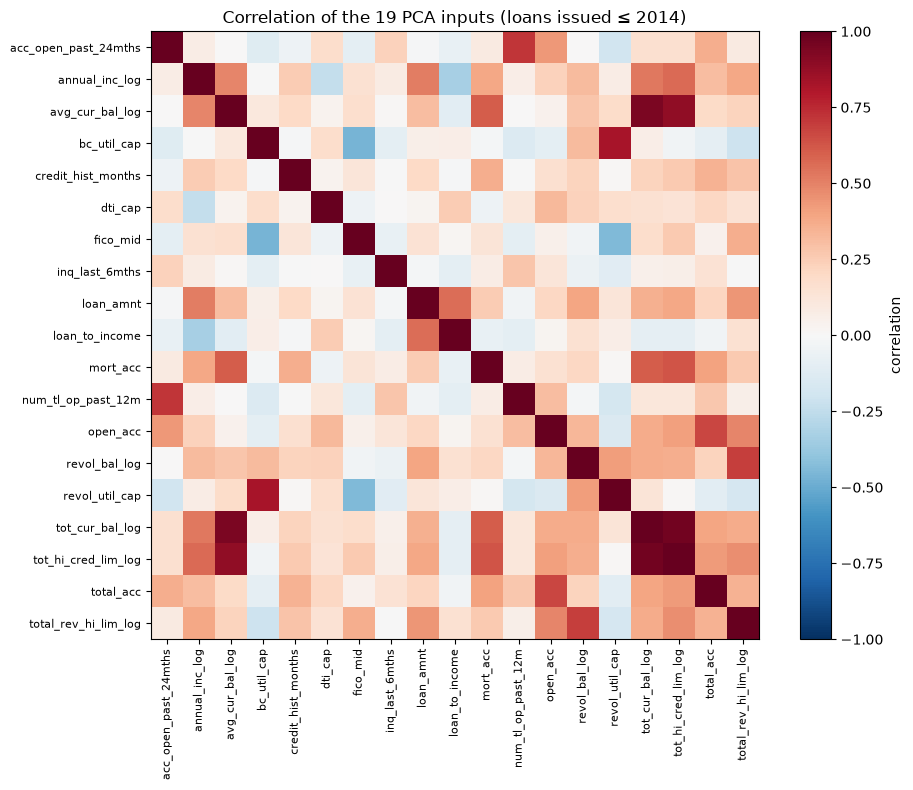

tot_cur_bal_log       tot_hi_cred_lim_log     0.97
avg_cur_bal_log       tot_cur_bal_log         0.94
                      tot_hi_cred_lim_log     0.89
bc_util_cap           revol_util_cap          0.82
acc_open_past_24mths  num_tl_op_past_12m      0.71
revol_bal_log         total_rev_hi_lim_log    0.69
open_acc              total_acc               0.67
mort_acc              tot_hi_cred_lim_log     0.63
                      tot_cur_bal_log         0.61
avg_cur_bal_log       mort_acc                0.61
annual_inc_log        tot_hi_cred_lim_log     0.56
loan_amnt             loan_to_income          0.56
annual_inc_log        tot_cur_bal_log         0.53
                      loan_amnt               0.52
dtype: float64


In [7]:
corr = Z_fit.corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns, fontsize=8)
fig.colorbar(im, ax=ax, label="correlation")
ax.set_title("Correlation of the 19 PCA inputs (loans issued ≤ 2014)")
plt.tight_layout()
fig.savefig("../reports/pca_correlation.png", dpi=120, bbox_inches="tight")
plt.show()

def top_pairs(corr, threshold=0.5):
    """Each pair of columns once, keeping only |correlation| >= threshold, strongest first."""
    upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))   # keep each pair once
    pairs = upper.stack()
    return pairs[pairs.abs() >= threshold].sort_values(key=abs, ascending=False).round(2)

print(top_pairs(corr))

### A6 Step 3: How many components?

PCA on the 19 standardized inputs (loans ≤ 2014). PC1 captures 5.16 columns' worth of variation (27.2%), then PC2–PC4 form a plateau (2.69 / 2.18 / 1.93), followed by a second drop at PC5 (1.20).
- Elbow → 4 components (63.0%); Kaiser (eigenvalue > 1) → 6 (75.1%); 70–80% cumulative → 6. PC7 (0.98) sits just below the Kaiser line.
- PC19 ≈ 0 and PC18 = 0.03: at least one input is almost a linear combination of others (the 0.89–0.97 balance/limit block), confirming the multicollinearity risk for the scorecard.
- The choice between 4 and 6 depends on whether PC5–PC6 are interpretable (next step).

,eigenvalue,share,cumulative
PC1,5.16,0.272,0.272
PC2,2.69,0.142,0.413
PC3,2.18,0.115,0.528
PC4,1.93,0.102,0.630
PC5,1.20,0.063,0.693
PC6,1.10,0.058,0.751
PC7,0.98,0.051,0.802
PC8,0.83,0.043,0.846
PC9,0.70,0.037,0.882
PC10,0.56,0.030,0.912


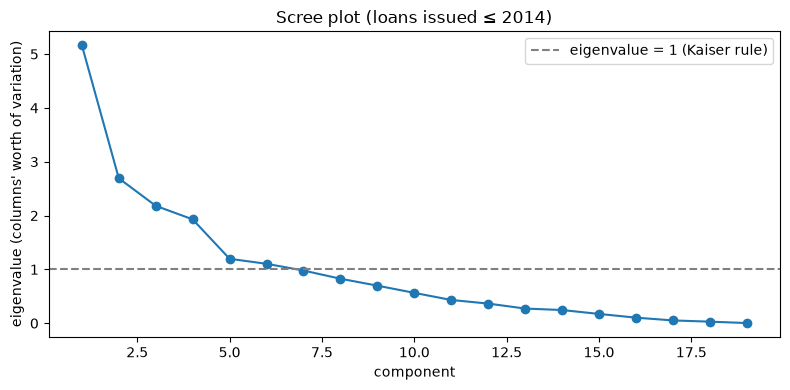

In [8]:
from sklearn.decomposition import PCA

pca = PCA().fit(Z_fit)                      # all 19 components, fitted on <= 2014
explained = pd.DataFrame({
    "eigenvalue": pca.explained_variance_.round(2),
    "share": pca.explained_variance_ratio_.round(3),
    "cumulative": pca.explained_variance_ratio_.cumsum().round(3),
}, index=[f"PC{i+1}" for i in range(len(PCA_COLS))])
display(explained)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(PCA_COLS) + 1), pca.explained_variance_, marker="o")
ax.axhline(1, color="grey", linestyle="--", label="eigenvalue = 1 (Kaiser rule)")
ax.set_xlabel("component")
ax.set_ylabel("eigenvalue (columns' worth of variation)")
ax.set_title("Scree plot (loans issued ≤ 2014)")
ax.legend()
plt.tight_layout()
fig.savefig("../reports/pca_scree.png", dpi=120, bbox_inches="tight")
plt.show()

### A6 Step 4: What each component means (loadings)

A loading is the correlation between an original column and a component's score; squared, it is the share of that column's variation captured by the component. |loading| ≥ 0.4 is treated as a main ingredient.
- **PC1 (27%), overall credit size**: total limits 0.91, balances 0.88, avg balance 0.75, mort_acc 0.67, income 0.67, card limits 0.66, account counts 0.56–0.61, loan amount 0.55, history 0.42. Established, higher-income, mortgage-holding borrowers.
- **PC2 (14%), using existing cards vs opening new ones**: revol_util 0.84, bc_util 0.77 vs acc_open_past_24mths −0.55, num_tl_op_past_12m −0.53. New accounts add limit and lower utilization.
- **PC3 (11.5%), credit stress**: dti 0.57, recent/open accounts 0.46–0.54, bc_util 0.42, fico −0.55.
- **PC4 (10%), size of the request**: loan_to_income 0.70, total_rev_hi_lim 0.52, loan_amnt 0.47.
- **PC5 (6%), income squeeze (weak)**: dti 0.46, income −0.43; partly by construction (dti = debt / income).
- **PC6, PC7**: single-column leftovers (loan_amnt 0.56; credit_hist_months 0.60). They pass Kaiser only because they carry about one column each.
- **PC19 ≈ 0**: tot_cur_bal 0.73, avg_cur_bal −0.64, open_acc −0.23. On the log scale avg_cur_bal ≈ tot_cur_bal − account count, so it is nearly redundant (drop candidate for the scorecard).

Conclusion: 4 clear components (63% of variation) plus a weak 5th (69%). Factor analysis decides between 4 and 5.

In [9]:
N_SHOW = 7
loadings = pd.DataFrame(pca.components_[:N_SHOW].T * np.sqrt(pca.explained_variance_[:N_SHOW]),
                        index=PCA_COLS,
                        columns=[f"PC{i+1}" for i in range(N_SHOW)]).round(2)
display(loadings.style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1))

for pc in loadings.columns:
    s = loadings[pc]
    main = s[s.abs() >= 0.4].sort_values(key=abs, ascending=False)
    print(f"{pc}: {main.to_dict()}")

w19 = pd.Series(pca.components_[18], index=PCA_COLS)
print("\nPC19 (near-zero variance) main weights:",
      w19[w19.abs() >= 0.2].sort_values(key=abs, ascending=False).round(2).to_dict())

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
acc_open_past_24mths,0.260000,-0.550000,0.540000,-0.240000,0.080000,0.190000,-0.080000
annual_inc_log,0.670000,0.060000,-0.260000,-0.180000,-0.430000,0.270000,-0.180000
avg_cur_bal_log,0.750000,0.270000,-0.300000,-0.330000,0.360000,0.030000,-0.020000
bc_util_cap,-0.020000,0.770000,0.420000,-0.250000,-0.070000,-0.020000,0.010000
credit_hist_months,0.420000,0.030000,-0.090000,0.110000,-0.380000,-0.290000,0.600000
dti_cap,0.170000,0.070000,0.570000,0.220000,0.460000,-0.390000,-0.000000
fico_mid,0.250000,-0.330000,-0.550000,0.380000,0.170000,-0.120000,-0.150000
inq_last_6mths,0.100000,-0.320000,0.190000,-0.260000,-0.080000,0.360000,0.180000
loan_amnt,0.550000,0.240000,-0.010000,0.470000,-0.030000,0.560000,0.120000
loan_to_income,-0.010000,0.210000,0.240000,0.700000,0.380000,0.360000,0.310000


PC1: {'tot_hi_cred_lim_log': 0.91, 'tot_cur_bal_log': 0.88, 'avg_cur_bal_log': 0.75, 'mort_acc': 0.67, 'annual_inc_log': 0.67, 'total_rev_hi_lim_log': 0.66, 'total_acc': 0.61, 'revol_bal_log': 0.56, 'open_acc': 0.56, 'loan_amnt': 0.55, 'credit_hist_months': 0.42}
PC2: {'revol_util_cap': 0.84, 'bc_util_cap': 0.77, 'acc_open_past_24mths': -0.55, 'num_tl_op_past_12m': -0.53, 'revol_bal_log': 0.4}
PC3: {'dti_cap': 0.57, 'fico_mid': -0.55, 'acc_open_past_24mths': 0.54, 'num_tl_op_past_12m': 0.48, 'open_acc': 0.46, 'bc_util_cap': 0.42}
PC4: {'loan_to_income': 0.7, 'total_rev_hi_lim_log': 0.52, 'loan_amnt': 0.47}
PC5: {'dti_cap': 0.46, 'annual_inc_log': -0.43}
PC6: {'loan_amnt': 0.56}
PC7: {'credit_hist_months': 0.6}

PC19 (near-zero variance) main weights: {'tot_cur_bal_log': 0.73, 'avg_cur_bal_log': -0.64, 'open_acc': -0.23}


### A6 Step 5: Is the data suitable for factor analysis?

FA explains the **shared** part of the columns through a few hidden factors (PCA summarizes all variation). Two checks:
- **Bartlett's test** (are the columns correlated at all?): p ≈ 0 → yes.
- **KMO** (are correlations explained by broadly shared factors rather than private pairwise links?): on 18 inputs (avg_cur_bal excluded as near-redundant, PC19 ≈ 0), overall 0.661 (mediocre). The weakest columns were the formula trio loan_to_income (0.29), loan_amnt (0.49) and annual_inc (0.54), linked by construction (loan_to_income = loan_amnt / income).
- Removing the derived loan_to_income (it remains a model feature) raised KMO to **0.724 (good)**: loan_amnt 0.49 → 0.87, annual_inc 0.54 → 0.79, confirming the formula link as the cause. All 17 columns are ≥ 0.5 (lowest: dti 0.58, itself partly a formula of income).

In [10]:
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo

FA_COLS = [c for c in PCA_COLS if c != "avg_cur_bal_log"]   # near-redundant (PC19 ~ 0)
Z_fa = Z_fit[FA_COLS]

chi2, p_value = calculate_bartlett_sphericity(Z_fa)
kmo_per_column, kmo_overall = calculate_kmo(Z_fa)

print(f"FA inputs: {len(FA_COLS)}")
print(f"Bartlett: chi2 = {chi2:,.0f}, p = {p_value:.3g}")
print(f"KMO overall: {kmo_overall:.3f}")
display(pd.Series(kmo_per_column, index=FA_COLS, name="KMO").round(2).sort_values())

FA inputs: 18
Bartlett: chi2 = 183,420, p = 0
KMO overall: 0.661


loan_to_income          0.29
loan_amnt               0.49
annual_inc_log          0.54
revol_util_cap          0.63
revol_bal_log           0.65
num_tl_op_past_12m      0.67
total_rev_hi_lim_log    0.67
acc_open_past_24mths    0.69
tot_cur_bal_log         0.71
tot_hi_cred_lim_log     0.72
bc_util_cap             0.73
dti_cap                 0.76
open_acc                0.77
total_acc               0.78
credit_hist_months      0.82
fico_mid                0.83
mort_acc                0.85
inq_last_6mths          0.86
Name: KMO, dtype: float64

In [11]:
FA_COLS = [c for c in FA_COLS if c != "loan_to_income"]     # derived from loan_amnt / income
Z_fa = Z_fit[FA_COLS]

chi2, p_value = calculate_bartlett_sphericity(Z_fa)
kmo_per_column, kmo_overall = calculate_kmo(Z_fa)

print(f"FA inputs: {len(FA_COLS)}")
print(f"Bartlett: chi2 = {chi2:,.0f}, p = {p_value:.3g}")
print(f"KMO overall: {kmo_overall:.3f}")
display(pd.Series(kmo_per_column, index=FA_COLS, name="KMO").round(2).sort_values())

FA inputs: 17
Bartlett: chi2 = 156,249, p = 0
KMO overall: 0.724


dti_cap                 0.58
revol_util_cap          0.62
revol_bal_log           0.64
num_tl_op_past_12m      0.66
total_rev_hi_lim_log    0.66
acc_open_past_24mths    0.68
tot_cur_bal_log         0.70
tot_hi_cred_lim_log     0.71
bc_util_cap             0.73
open_acc                0.77
total_acc               0.78
annual_inc_log          0.79
credit_hist_months      0.82
fico_mid                0.83
mort_acc                0.84
inq_last_6mths          0.84
loan_amnt               0.87
Name: KMO, dtype: float64

In [12]:
SPEC["fa"] = {
    "columns": FA_COLS,
    "excluded_from_fa": {
        "avg_cur_bal_log": "near-exact combination of tot_cur_bal and account count (PCA PC19 eigenvalue ~0); "
                           "unstable matrix inverse / Heywood risk",
        "loan_to_income": "formula of loan_amnt / income: KMO 0.29; removing it raised overall KMO 0.661 -> 0.724 "
                          "(loan_amnt 0.49 -> 0.87, annual_inc 0.54 -> 0.79)",
    },
    "bartlett_p": float(p_value),
    "kmo_overall": round(float(kmo_overall), 3),
}
with open("../reports/a6_spec.json", "w") as f:
    json.dump(SPEC, f, indent=2)
print("saved |", len(FA_COLS), "FA inputs")

saved | 17 FA inputs


### A6 Step 6: Factor analysis (4 factors, promax)

Fitted with minres on 17 standardized inputs (loans ≤ 2014). Rotation turns the factor axes so that each column loads mainly on one factor; promax allows factors to correlate.
- **4 factors**:
  - F1 debt size (tot_cur_bal 0.96, tot_hi_cred_lim 0.95, mort_acc 0.75, income 0.62)
  - F2 card utilization (revol_util 0.94, bc_util 0.88, fico −0.56)
  - F3 card size (total_rev_hi_lim 0.94, revol_bal 0.79, open_acc 0.49)
  - F4 credit-seeking (acc_open_past_24mths 0.84, num_tl_op_past_12m 0.73, open_acc 0.48, total_acc 0.43)
- Rotation separated card utilization and new-account activity, which PCA had bundled into one contrast axis (PC2).
- **5 factors rejected**: F5 (dti 0.64, income −0.54) mainly reflects the dti = debt/income formula (the reason loan_to_income was excluded from FA), and the solution is less stable.
- **No Heywood case**: communalities from an unrotated fit (rotation-invariant) are all ≤ 0.97. Values above 1 seen earlier came from combining loadings with a mis-ordered factor-correlation matrix.
- **Library check**: factor_analyzer's phi_ lists factors in a different order than its loadings (F3/F4 swapped). Confirmed by correlating actual factor scores and by reproducing the unrotated communalities after reordering (max difference 0.002).
- **Promax vs varimax**: factor score correlation debt size ↔ card size = 0.56 (≥ 0.3 rule) → promax. Varimax gives the same four groups, so the names are robust.
- Low communalities (inq_last_6mths 0.10, credit_hist_months 0.15, dti 0.18, loan_amnt 0.31): mostly unique information; these stay separate model features.

In [13]:
from factor_analyzer import FactorAnalyzer

def run_fa(Z, n_factors, rotation="promax"):
    """Fit FA, print main ingredients per factor, and return loadings, communalities, factor correlations."""
    fa = FactorAnalyzer(n_factors=n_factors, rotation=rotation, method="minres")
    fa.fit(Z)
    names = [f"F{i+1}" for i in range(n_factors)]
    loadings = pd.DataFrame(fa.loadings_, index=Z.columns, columns=names).round(2)
    communality = pd.Series(fa.get_communalities(), index=Z.columns, name="communality").round(2)
    phi = getattr(fa, "phi_", None)                               # factor correlations (oblique only)
    phi = pd.DataFrame(phi, index=names, columns=names).round(2) if phi is not None else None

    print(f"===== {n_factors} factors, {rotation} =====")
    for f in names:
        s = loadings[f]
        main = s[s.abs() >= 0.4].sort_values(key=abs, ascending=False)
        print(f"{f}: {main.to_dict()}")
    return fa, loadings, communality, phi

fa4, load4, comm4, phi4 = run_fa(Z_fa, 4)
display(phi4)
fa5, load5, comm5, phi5 = run_fa(Z_fa, 5)
display(phi5)
display(pd.DataFrame({"comm_4": comm4, "comm_5": comm5}).sort_values("comm_4"))

/home/kalki/credit-risk-takehome/.venv/lib/python3.12/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


===== 4 factors, promax =====
F1: {'tot_cur_bal_log': 0.96, 'tot_hi_cred_lim_log': 0.95, 'mort_acc': 0.75, 'annual_inc_log': 0.62}
F2: {'revol_util_cap': 0.94, 'bc_util_cap': 0.88, 'fico_mid': -0.56}
F3: {'total_rev_hi_lim_log': 0.94, 'revol_bal_log': 0.79, 'open_acc': 0.49}
F4: {'acc_open_past_24mths': 0.84, 'num_tl_op_past_12m': 0.73, 'open_acc': 0.48, 'total_acc': 0.43}


,F1,F2,F3,F4
F1,1.00,-0.18,0.10,0.52
F2,-0.18,1.00,-0.01,0.05
F3,0.10,-0.01,1.00,0.20
F4,0.52,0.05,0.20,1.00


===== 5 factors, promax =====
F1: {'tot_cur_bal_log': 1.07, 'tot_hi_cred_lim_log': 1.06, 'mort_acc': 0.71}
F2: {'total_rev_hi_lim_log': 1.03, 'revol_bal_log': 0.88, 'loan_amnt': 0.53, 'annual_inc_log': 0.43}
F3: {'revol_util_cap': 0.92, 'bc_util_cap': 0.85, 'fico_mid': -0.58}
F4: {'acc_open_past_24mths': 0.85, 'num_tl_op_past_12m': 0.78}
F5: {'dti_cap': 0.64, 'annual_inc_log': -0.54}


/home/kalki/credit-risk-takehome/.venv/lib/python3.12/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,F1,F2,F3,F4,F5
F1,1.00,-0.11,0.27,0.68,-0.04
F2,-0.11,1.00,-0.16,-0.07,0.02
F3,0.27,-0.16,1.00,0.18,0.25
F4,0.68,-0.07,0.18,1.00,0.11
F5,-0.04,0.02,0.25,0.11,1.00


,comm_4,comm_5
credit_hist_months,0.11,0.09
inq_last_6mths,0.11,0.13
dti_cap,0.19,0.43
loan_amnt,0.23,0.33
total_acc,0.33,0.27
fico_mid,0.38,0.44
annual_inc_log,0.39,0.62
open_acc,0.48,0.41
num_tl_op_past_12m,0.54,0.62
mort_acc,0.60,0.52


In [14]:
def true_communalities(Z, n_factors):
    """Communalities from an unrotated fit (rotation doesn't change them; the shortcut is exact here)."""
    fa = FactorAnalyzer(n_factors=n_factors, rotation=None, method="minres")
    fa.fit(Z)
    return pd.Series((fa.loadings_ ** 2).sum(axis=1), index=Z.columns)

def oblique_communalities(fa):
    """Correct communalities for promax: account for the factor correlations (phi)."""
    L = fa.loadings_
    return pd.Series(np.diag(L @ fa.phi_ @ L.T), index=FA_COLS)

check = pd.DataFrame({
    "true_4": true_communalities(Z_fa, 4),
    "promax_correct_4": oblique_communalities(fa4),
    "true_5": true_communalities(Z_fa, 5),
    "promax_correct_5": oblique_communalities(fa5),
}).round(3).sort_values("true_5")
display(check)

/home/kalki/credit-risk-takehome/.venv/lib/python3.12/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/kalki/credit-risk-takehome/.venv/lib/python3.12/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,true_4,promax_correct_4,true_5,promax_correct_5
inq_last_6mths,0.099,0.120,0.114,0.136
credit_hist_months,0.152,0.105,0.150,0.075
loan_amnt,0.310,0.181,0.363,0.299
fico_mid,0.401,0.389,0.417,0.414
dti_cap,0.176,0.186,0.432,0.464
mort_acc,0.472,0.620,0.446,0.552
total_acc,0.467,0.511,0.462,0.364
num_tl_op_past_12m,0.522,0.514,0.577,0.555
open_acc,0.595,0.595,0.605,0.420
acc_open_past_24mths,0.704,0.689,0.726,0.697


In [15]:
# 1. Correlations of the actual factor scores (independent of the library's phi)
scores4 = pd.DataFrame(fa4.transform(Z_fa), columns=["F1", "F2", "F3", "F4"], index=Z_fa.index)
print("Library phi (promax):")
display(phi4)
print("Correlation of promax factor scores:")
display(scores4.corr().round(2))

# 2. Same 4-factor model with varimax: are the groups of ingredients the same?
fa4v, load4v, comm4v, _ = run_fa(Z_fa, 4, rotation="varimax")

Library phi (promax):


/home/kalki/credit-risk-takehome/.venv/lib/python3.12/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,F1,F2,F3,F4
F1,1.00,-0.18,0.10,0.52
F2,-0.18,1.00,-0.01,0.05
F3,0.10,-0.01,1.00,0.20
F4,0.52,0.05,0.20,1.00


Correlation of promax factor scores:


,F1,F2,F3,F4
F1,1.00,-0.17,0.56,0.13
F2,-0.17,1.00,0.03,-0.05
F3,0.56,0.03,1.00,0.20
F4,0.13,-0.05,0.20,1.00


/home/kalki/credit-risk-takehome/.venv/lib/python3.12/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


===== 4 factors, varimax =====
F1: {'tot_hi_cred_lim_log': 0.92, 'tot_cur_bal_log': 0.89, 'mort_acc': 0.68, 'annual_inc_log': 0.62, 'loan_amnt': 0.43}
F2: {'revol_util_cap': 0.92, 'bc_util_cap': 0.86, 'fico_mid': -0.56}
F3: {'acc_open_past_24mths': 0.84, 'num_tl_op_past_12m': 0.72, 'open_acc': 0.54, 'total_acc': 0.48}
F4: {'total_rev_hi_lim_log': 0.85, 'revol_bal_log': 0.74, 'open_acc': 0.49}


In [16]:
order = ["F1", "F2", "F4", "F3"]                                  # phi's F4 is the loadings' F3
phi4_reordered = phi4.loc[order, order].values                     # (rounded to 2 decimals)
comm_check = pd.DataFrame({
    "true_4": true_communalities(Z_fa, 4),
    "promax_reordered": np.diag(fa4.loadings_ @ phi4_reordered @ fa4.loadings_.T),
}, index=FA_COLS).round(3)
comm_check["difference"] = (comm_check["promax_reordered"] - comm_check["true_4"]).round(3)
display(comm_check)
print("largest difference:", comm_check["difference"].abs().max())

/home/kalki/credit-risk-takehome/.venv/lib/python3.12/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,true_4,promax_reordered,difference
acc_open_past_24mths,0.704,0.704,0.000
annual_inc_log,0.421,0.421,0.000
bc_util_cap,0.769,0.768,-0.001
credit_hist_months,0.152,0.151,-0.001
dti_cap,0.176,0.177,0.001
fico_mid,0.401,0.401,0.000
inq_last_6mths,0.099,0.100,0.001
loan_amnt,0.310,0.310,0.000
mort_acc,0.472,0.473,0.001
num_tl_op_past_12m,0.522,0.522,0.000


largest difference: 0.002


In [17]:
import joblib

FACTOR_NAMES = {"F1": "debt_size", "F2": "card_utilization", "F3": "card_size", "F4": "credit_seeking"}
phi_fixed = pd.DataFrame(phi4.loc[order, order].values, index=list(FACTOR_NAMES), columns=list(FACTOR_NAMES))

SPEC["fa"].update({
    "n_factors": 4,
    "rotation": "promax",
    "factor_names": FACTOR_NAMES,
    "loadings": load4.to_dict(),
    "factor_correlations": phi_fixed.round(2).to_dict(),
    "communalities": true_communalities(Z_fa, 4).round(3).to_dict(),
    "notes": [
        "5 factors rejected: F5 (dti 0.64, income -0.54) mainly reflects the dti = debt/income formula, "
        "the same kind of private link that removed loan_to_income from FA; also less stable.",
        "factor_analyzer's phi_ lists factors in a different order than loadings_ (F3/F4 swapped here); "
        "verified by reproducing the unrotated communalities (max difference 0.002).",
        "varimax gives the same four groups, so the factor names are robust to the rotation choice.",
    ],
})
with open("../reports/a6_spec.json", "w") as f:
    json.dump(SPEC, f, indent=2)
joblib.dump({"scaler": scaler, "fa": fa4, "fa_cols": FA_COLS, "pca_cols": PCA_COLS, "pca_log1p": PCA_LOG},
            "../data/interim/a6_factor_model.joblib")
print("saved")

saved


/home/kalki/credit-risk-takehome/.venv/lib/python3.12/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [18]:
from sklearn.metrics import roc_auc_score

# 1. Factor scores for all loans (fitted objects from <= 2014, applied unchanged)
Z_all = pd.DataFrame(scaler.transform(pca_matrix(train)), columns=PCA_COLS, index=train.index)[FA_COLS]
score_cols = [f"factor_{name}" for name in FACTOR_NAMES.values()]
train[score_cols] = fa4.transform(Z_all)

# 2. How each factor relates to default, in 2013-14 and in 2015
def factor_auc(df, cols, target=TARGET):
    rows = []
    for c in cols:
        auc = roc_auc_score(df[target], df[c])
        rows.append({"factor": c, "auc": round(max(auc, 1 - auc), 3),
                     "direction": "higher = riskier" if auc > 0.5 else "higher = safer"})
    return pd.DataFrame(rows).set_index("factor")

is_fit = train["issue_dt"] <= FIT_CUTOFF
display(factor_auc(train[is_fit], score_cols).join(
        factor_auc(train[~is_fit], score_cols), lsuffix="_2013_14", rsuffix="_2015"))

# 3. Save
train.to_parquet("../data/interim/train_a6.parquet", index=False)
SPEC["fa"]["score_columns"] = score_cols
with open("../reports/a6_spec.json", "w") as f:
    json.dump(SPEC, f, indent=2)
print("saved")

/home/kalki/credit-risk-takehome/.venv/lib/python3.12/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/tmp/ipykernel_392312/3012181119.py:18: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  display(factor_auc(train[is_fit], score_cols).join(


,auc_2013_14,direction_2013_14,auc_2015,direction_2015
factor,,,,
factor_debt_size,0.560,higher = safer,0.558,higher = safer
factor_card_utilization,0.579,higher = riskier,0.575,higher = riskier
factor_card_size,0.507,higher = safer,0.504,higher = riskier
factor_credit_seeking,0.579,higher = riskier,0.586,higher = riskier


saved


### A6 addition: Spearman correlation and multicollinearity (VIF)

- **Spearman** (rank-based, robust to outliers) confirms the Pearson blocks: tot_cur_bal ↔ tot_hi_cred_lim 0.98, avg_cur_bal 0.90–0.94, bc_util ↔ revol_util 0.81, revol_bal ↔ total_rev_hi_lim 0.78 (Pearson 0.69), acc_open ↔ num_tl_op 0.71.
- **VIF** (how well each column is predicted by all the others; > 10 severe): tot_cur_bal 212, avg_cur_bal 168.5, tot_hi_cred_lim 25, open_acc 24.6 (avg_cur_bal = balance / number of accounts), and the loan_amnt / income / loan_to_income formula trio at 6.6–8.0. All others ≤ 5.3.
- The same two clusters were flagged independently by PCA (PC19 ≈ 0) and KMO. Such redundancy makes linear-model weights unstable, which is why dimension reduction is useful here and why the scorecard must drop or combine these columns.

In [19]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

spear = Z_fit.corr(method="spearman")
print("Strongest Spearman pairs:")
print(top_pairs(spear))

vif = pd.Series([variance_inflation_factor(Z_fit.values, i) for i in range(Z_fit.shape[1])],
                index=PCA_COLS).round(1).sort_values(ascending=False)
print("\nVIF (1 = independent, > 5 strong, > 10 severe):")
display(vif)

Strongest Spearman pairs:
tot_cur_bal_log       tot_hi_cred_lim_log     0.98
avg_cur_bal_log       tot_cur_bal_log         0.94
                      tot_hi_cred_lim_log     0.90
bc_util_cap           revol_util_cap          0.81
revol_bal_log         total_rev_hi_lim_log    0.78
acc_open_past_24mths  num_tl_op_past_12m      0.71
open_acc              total_acc               0.67
mort_acc              tot_hi_cred_lim_log     0.65
                      tot_cur_bal_log         0.64
avg_cur_bal_log       mort_acc                0.63
loan_amnt             loan_to_income          0.61
annual_inc_log        tot_hi_cred_lim_log     0.56
                      tot_cur_bal_log         0.54
dtype: float64

VIF (1 = independent, > 5 strong, > 10 severe):


tot_cur_bal_log         212.0
avg_cur_bal_log         168.5
tot_hi_cred_lim_log      25.0
open_acc                 24.6
loan_amnt                 8.0
annual_inc_log            7.0
loan_to_income            6.6
total_rev_hi_lim_log      5.3
revol_util_cap            4.6
revol_bal_log             4.6
bc_util_cap               3.3
acc_open_past_24mths      2.4
total_acc                 2.4
mort_acc                  2.1
num_tl_op_past_12m        2.1
fico_mid                  1.7
dti_cap                   1.6
credit_hist_months        1.3
inq_last_6mths            1.1
dtype: float64

In [20]:
vif_fa = pd.Series([variance_inflation_factor(Z_fit[FA_COLS].values, i) for i in range(len(FA_COLS))],
                   index=FA_COLS).round(1).sort_values(ascending=False)
display(vif_fa.head(6))

tot_hi_cred_lim_log     25.0
tot_cur_bal_log         21.8
total_rev_hi_lim_log     5.3
revol_bal_log            4.6
revol_util_cap           4.6
bc_util_cap              3.3
dtype: float64

### A6 addition: Effect of the outlier treatment on PCA

PCA repeated on the untreated inputs (raw values after A1 cleaning; no caps, no logs), standardized the same way.
- **Same components**: similarity of directions (|cosine|) between treated and untreated PC1/PC2/PC3 = 0.99 / 0.92 / 0.90. PC2 and PC3 exchange some content (0.35 / 0.36).
- **Cleaner after treatment**: PC1 explains 27.2% vs 23.2% untreated, and annual_inc loads 0.67 vs 0.43. Extreme incomes weaken income's correlation with the debt block.
- The most extreme untreated value sits 96.5 SD from the mean (the $7.5M income), weighing as much as ~9,300 typical loans in that column's variance. It does not create its own component because it inflates the SD used for standardization (masking), so its damage appears as weakened correlations.
- Conclusion: the treatment does not change what the components mean (the structure is robust), but makes them cleaner and less dependent on a few loans.

In [21]:
def untreated_matrix(df):
    """The 19 PCA inputs without caps or logs (raw values after A1 cleaning)."""
    X = pd.DataFrame(index=df.index)
    for c in PCA_COLS:
        if c == "loan_to_income":
            X[c] = df["loan_amnt"] / df["annual_inc"]          # uncapped ratio
        elif c.endswith("_log") or c.endswith("_cap"):
            X[c] = df[c.rsplit("_", 1)[0]]                       # e.g. annual_inc_log -> annual_inc
        else:
            X[c] = df[c]                                         # count fields without log1p
    return X

Z_raw = pd.DataFrame(StandardScaler().fit_transform(untreated_matrix(fit)), columns=PCA_COLS, index=fit.index)
pca_raw = PCA().fit(Z_raw)

print("Explained variance share, PC1-PC5:")
display(pd.DataFrame({"treated": pca.explained_variance_ratio_[:5],
                      "untreated": pca_raw.explained_variance_ratio_[:5]},
                     index=[f"PC{i+1}" for i in range(5)]).round(3))

raw_load = pd.DataFrame(pca_raw.components_[:3].T * np.sqrt(pca_raw.explained_variance_[:3]),
                        index=PCA_COLS, columns=["PC1", "PC2", "PC3"]).round(2)
for pc in raw_load.columns:
    s = raw_load[pc]
    print(f"untreated {pc}:", s[s.abs() >= 0.4].sort_values(key=abs, ascending=False).to_dict())

similarity = np.abs(pca.components_[:3] @ pca_raw.components_[:3].T).round(2)
print("\nSimilarity of directions (rows = treated PC1-3, cols = untreated PC1-3; 1 = same):")
display(pd.DataFrame(similarity, index=["T-PC1", "T-PC2", "T-PC3"], columns=["U-PC1", "U-PC2", "U-PC3"]))
print("largest |z| in untreated input:", round(Z_raw.abs().max().max(), 1))

Explained variance share, PC1-PC5:


,treated,untreated
PC1,0.272,0.232
PC2,0.142,0.140
PC3,0.115,0.114
PC4,0.102,0.098
PC5,0.063,0.062


untreated PC1: {'tot_hi_cred_lim_log': 0.9, 'tot_cur_bal_log': 0.87, 'avg_cur_bal_log': 0.67, 'total_rev_hi_lim_log': 0.65, 'mort_acc': 0.62, 'total_acc': 0.57, 'revol_bal_log': 0.49, 'open_acc': 0.48, 'loan_amnt': 0.48, 'annual_inc_log': 0.43}
untreated PC2: {'acc_open_past_24mths': 0.69, 'num_tl_op_past_12m': 0.65, 'revol_util_cap': -0.64, 'bc_util_cap': -0.56, 'open_acc': 0.53, 'avg_cur_bal_log': -0.45, 'total_acc': 0.44}
untreated PC3: {'bc_util_cap': 0.68, 'revol_util_cap': 0.64, 'fico_mid': -0.59, 'dti_cap': 0.56}

Similarity of directions (rows = treated PC1-3, cols = untreated PC1-3; 1 = same):


,U-PC1,U-PC2,U-PC3
T-PC1,0.99,0.04,0.09
T-PC2,0.07,0.92,0.35
T-PC3,0.06,0.36,0.90


largest |z| in untreated input: 96.5
